#### Cell 1 – Load and inspect transaction data

Load the complete processed transaction dataset and inspect the basket and product identifiers, missing values, duplicate basket-product combinations, and dataset dimensions. These checks will help us construct accurate basket-level transactions without inflating product frequencies.

In [1]:
import pandas as pd

data_path = "../data/processed/transactions_enriched.csv"

transactions = pd.read_csv(data_path)

print("Dataset shape:", transactions.shape)

print("\nRequired columns:")
print(transactions[["BASKET_ID", "PRODUCT_ID"]].dtypes)

print("\nMissing identifiers:")
print(transactions[["BASKET_ID", "PRODUCT_ID"]].isna().sum())

print("\nUnique baskets:", transactions["BASKET_ID"].nunique())
print("Unique products:", transactions["PRODUCT_ID"].nunique())

print(
    "\nDuplicate basket-product combinations:",
    transactions.duplicated(["BASKET_ID", "PRODUCT_ID"]).sum()
)

/tmp/ipykernel_2630634/2833075681.py:5: DtypeWarning: Columns (12,13) have mixed types. Specify dtype option on import or set low_memory=False.
  transactions = pd.read_csv(data_path)


Dataset shape: (2595732, 24)

Required columns:
BASKET_ID     int64
PRODUCT_ID    int64
dtype: object

Missing identifiers:
BASKET_ID     0
PRODUCT_ID    0
dtype: int64

Unique baskets: 276484
Unique products: 92339

Duplicate basket-product combinations: 0


#### Cell 2 – Construct basket-level transactions

Group products by basket and remove duplicate product entries within each basket. Summarise basket sizes and product frequencies to assess the structure and sparsity of the data before selecting mining parameters.

In [2]:
basket_transactions = (
    transactions.groupby("BASKET_ID")["PRODUCT_ID"]
    .apply(lambda x: sorted(set(x)))
)

basket_sizes = basket_transactions.apply(len)
product_frequency = (
    transactions.groupby("PRODUCT_ID")["BASKET_ID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Total baskets:", len(basket_transactions))
print("Unique products:", product_frequency.size)

print("\nBasket size statistics:")
display(basket_sizes.describe())

print("\nLargest basket sizes:")
display(basket_sizes.nlargest(10))

print("\nTop 10 most frequently purchased products:")
display(product_frequency.head(10))

Total baskets: 276484
Unique products: 92339

Basket size statistics:


count    276484.000000
mean          9.388362
std          12.283792
min           1.000000
25%           2.000000
50%           5.000000
75%          12.000000
max         168.000000
Name: PRODUCT_ID, dtype: float64


Largest basket sizes:


BASKET_ID
30983766334    168
33347880492    161
33655186256    155
31242648741    153
28210676830    150
41560100381    147
33094862148    146
27798435271    144
41026060523    144
40314544302    138
Name: PRODUCT_ID, dtype: int64


Top 10 most frequently purchased products:


PRODUCT_ID
1082185    29778
6534178    19820
1029743    14430
995242     12542
1106523     9826
981760      9126
1133018     7315
883404      6904
951590      6138
826249      5505
Name: BASKET_ID, dtype: int64

#### Cell 3 – Examine product frequency and descriptions

Examine how frequently products occur across baskets and identify the descriptions of the most common products. This will help us assess sparsity and choose a practical mining strategy.

In [3]:
top_product_ids = product_frequency.head(10).index

product_details = (
    transactions[transactions["PRODUCT_ID"].isin(top_product_ids)]
    [["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC", "BRAND"]]
    .drop_duplicates()
    .sort_values("PRODUCT_ID")
)

print("Product frequency distribution:")
display(product_frequency.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nProducts appearing in different proportions of baskets:")
for threshold in [0.01, 0.005, 0.001]:
    count = (product_frequency >= len(basket_transactions) * threshold).sum()
    print(f"At least {threshold:.1%} of baskets: {count:,} products")

print("\nDescriptions of the 10 most frequent products:")
display(product_details)

Product frequency distribution:


count    92339.000000
mean        28.110896
std        191.960855
min          1.000000
25%          1.000000
50%          3.000000
75%         13.000000
90%         57.000000
95%        115.000000
99%        365.620000
max      29778.000000
Name: BASKET_ID, dtype: float64


Products appearing in different proportions of baskets:
At least 1.0% of baskets: 50 products
At least 0.5% of baskets: 124 products
At least 0.1% of baskets: 1,487 products

Descriptions of the 10 most frequent products:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND
5,826249,BAKED BREAD/BUNS/ROLLS,HAMBURGER BUNS,Private
280,883404,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,Private
67,951590,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,National
15,981760,EGGS,EGGS - X-LARGE,Private
830,995242,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private
233,1029743,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private
3,1082185,TROPICAL FRUIT,BANANAS,National
40,1106523,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private
2259,1133018,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private
5378,6534178,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,Private


#### Cell 4 – Inspect candidate products for mining

Examine products appearing in at least 0.5% of baskets and check whether their product descriptions are available. This will help us assess whether a manageable product-level analysis can produce interpretable rules.

In [4]:
min_product_frequency = int(len(basket_transactions) * 0.005)

candidate_products = product_frequency[
    product_frequency >= min_product_frequency
]

candidate_details = (
    transactions[transactions["PRODUCT_ID"].isin(candidate_products.index)]
    [["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC", "BRAND"]]
    .drop_duplicates(subset="PRODUCT_ID")
)

print("Minimum basket frequency:", min_product_frequency)
print("Candidate products:", len(candidate_products))

print("\nProduct description availability:")
display(candidate_details[
    ["COMMODITY_DESC", "SUB_COMMODITY_DESC", "BRAND"]
].isna().sum())

print("\nCandidate product examples:")
display(
    candidate_details
    .merge(
        candidate_products.rename("basket_frequency"),
        on="PRODUCT_ID"
    )
    .sort_values("basket_frequency", ascending=False)
    .head(20)
)

Minimum basket frequency: 1382
Candidate products: 124

Product description availability:


COMMODITY_DESC        0
SUB_COMMODITY_DESC    0
BRAND                 0
dtype: int64


Candidate product examples:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,basket_frequency
2,1082185,TROPICAL FRUIT,BANANAS,National,29778
117,6534178,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,Private,19820
26,1029743,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,14430
56,995242,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,12542
7,1106523,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,9826
4,981760,EGGS,EGGS - X-LARGE,Private,9126
93,1133018,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,7315
30,883404,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,Private,6904
11,951590,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,National,6138
3,826249,BAKED BREAD/BUNS/ROLLS,HAMBURGER BUNS,Private,5505


#### Cell 5 – Check candidate product categories

Inspect the category distribution of the 124 candidate products and identify coupon/miscellaneous entries and blank product descriptions. This will help us decide whether any non-product records should be excluded from basket mining.

In [5]:
candidate_analysis = (
    candidate_details
    .merge(
        candidate_products.rename("basket_frequency"),
        on="PRODUCT_ID"
    )
)

print("Candidate products by commodity category:")
display(
    candidate_analysis["COMMODITY_DESC"]
    .fillna("Missing")
    .replace("", "Blank")
    .value_counts()
    .head(20)
)

print("\nCoupon/miscellaneous candidate products:")
display(
    candidate_analysis[
        candidate_analysis["COMMODITY_DESC"].eq("COUPON/MISC ITEMS")
    ]
)

print("\nProducts with blank descriptions:")
display(
    candidate_analysis[
        candidate_analysis["COMMODITY_DESC"].fillna("").eq("")
        | candidate_analysis["SUB_COMMODITY_DESC"].fillna("").eq("")
    ]
)

Candidate products by commodity category:


COMMODITY_DESC
SOFT DRINKS                  11
FLUID MILK PRODUCTS          10
CHEESE                        8
BAKED BREAD/BUNS/ROLLS        7
TOMATOES                      5
ONIONS                        4
EGGS                          4
VEGETABLES - ALL OTHERS       4
POTATOES                      3
SALAD MIX                     3
BAG SNACKS                    3
MILK BY-PRODUCTS              3
CITRUS                        3
PAPER TOWELS                  2
REFRGRATD JUICES/DRNKS        2
CANDY - CHECKLANE             2
APPLES                        2
VEGETABLES - SHELF STABLE     2
COUPON/MISC ITEMS             2
BEEF                          2
Name: count, dtype: int64


Coupon/miscellaneous candidate products:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,basket_frequency
117,6534178,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,Private,19820
122,6533889,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,Private,1453



Products with blank descriptions:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,basket_frequency


#### Cell 6 – Prepare the product baskets

Exclude coupon/miscellaneous entries and construct the cleaned basket transactions. Compare the resulting basket and product counts with the original data to verify the effect of this exclusion.

In [6]:
transactions_for_mining = transactions[
    transactions["COMMODITY_DESC"] != "COUPON/MISC ITEMS"
].copy()

clean_basket_transactions = (
    transactions_for_mining.groupby("BASKET_ID")["PRODUCT_ID"]
    .apply(lambda x: sorted(set(x)))
)

clean_product_frequency = (
    transactions_for_mining.groupby("PRODUCT_ID")["BASKET_ID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Original transaction records:", len(transactions))
print("Records retained:", len(transactions_for_mining))
print("Records excluded:", len(transactions) - len(transactions_for_mining))

print("\nOriginal baskets:", len(basket_transactions))
print("Baskets after exclusion:", len(clean_basket_transactions))

print("\nOriginal unique products:", len(product_frequency))
print("Products after exclusion:", len(clean_product_frequency))

print("\nCleaned basket size statistics:")
display(clean_basket_transactions.apply(len).describe())

Original transaction records: 2595732
Records retained: 2567883
Records excluded: 27849

Original baskets: 276484
Baskets after exclusion: 253991

Original unique products: 92339
Products after exclusion: 92211

Cleaned basket size statistics:


count    253991.000000
mean         10.110134
std          12.537521
min           1.000000
25%           2.000000
50%           5.000000
75%          13.000000
max         168.000000
Name: PRODUCT_ID, dtype: float64

#### Cell 7 – Validate the excluded baskets

Identify how many baskets contained only coupon/miscellaneous records and how many contained both these records and ordinary products. This will help us determine whether excluding the category removes valid shopping baskets.

In [7]:
excluded_mask = transactions["COMMODITY_DESC"].eq("COUPON/MISC ITEMS")

basket_exclusion_check = (
    transactions.assign(is_excluded=excluded_mask)
    .groupby("BASKET_ID")["is_excluded"]
    .agg(["sum", "count"])
)

basket_exclusion_check["only_excluded"] = (
    basket_exclusion_check["sum"] == basket_exclusion_check["count"]
)

basket_exclusion_check["contains_excluded"] = (
    basket_exclusion_check["sum"] > 0
)

print("Baskets containing excluded records:",
      basket_exclusion_check["contains_excluded"].sum())

print("\nBaskets containing only excluded records:",
      basket_exclusion_check["only_excluded"].sum())

print("\nBaskets containing both excluded and ordinary records:",
      (
          basket_exclusion_check["contains_excluded"]
          & ~basket_exclusion_check["only_excluded"]
      ).sum())

print("\nExcluded records per affected basket:")
display(
    basket_exclusion_check.loc[
        basket_exclusion_check["contains_excluded"], "sum"
    ].describe()
)

Baskets containing excluded records: 27705

Baskets containing only excluded records: 22493

Baskets containing both excluded and ordinary records: 5212

Excluded records per affected basket:


count    27705.000000
mean         1.005198
std          0.074859
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          3.000000
Name: sum, dtype: float64

#### Cell 8 – Finalise candidate products

Recalculate product frequencies using the cleaned transactions and select products appearing in at least 0.5% of retained baskets. This ensures the candidate set and frequency threshold reflect the actual mining dataset.

In [8]:
min_product_frequency = int(len(clean_basket_transactions) * 0.005)

candidate_products = clean_product_frequency[
    clean_product_frequency >= min_product_frequency
]

candidate_details = (
    transactions_for_mining[
        transactions_for_mining["PRODUCT_ID"].isin(candidate_products.index)
    ][["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC", "BRAND"]]
    .drop_duplicates(subset="PRODUCT_ID")
)

print("Cleaned baskets:", len(clean_basket_transactions))
print("Minimum product frequency:", min_product_frequency)
print("Candidate products:", len(candidate_products))

print("\nCandidate category distribution:")
display(candidate_details["COMMODITY_DESC"].value_counts())

print("\nCandidate product examples:")
display(
    candidate_details
    .merge(candidate_products.rename("basket_frequency"), on="PRODUCT_ID")
    .sort_values("basket_frequency", ascending=False)
    .head(15)
)

Cleaned baskets: 253991
Minimum product frequency: 1269
Candidate products: 137

Candidate category distribution:


COMMODITY_DESC
SOFT DRINKS                       13
FLUID MILK PRODUCTS               10
CHEESE                             8
BAKED BREAD/BUNS/ROLLS             7
VEGETABLES - ALL OTHERS            5
TOMATOES                           5
CITRUS                             4
EGGS                               4
ONIONS                             4
BAG SNACKS                         4
REFRGRATD JUICES/DRNKS             3
MILK BY-PRODUCTS                   3
SALAD MIX                          3
POTATOES                           3
WATER - CARBONATED/FLVRD DRINK     2
BEEF                               2
MARGARINES                         2
TROPICAL FRUIT                     2
CRACKERS/MISC BKD FD               2
DELI MEATS                         2
VEGETABLES - SHELF STABLE          2
PAPER TOWELS                       2
SUGARS/SWEETNERS                   2
CANDY - CHECKLANE                  2
VEGETABLES SALAD                   2
APPLES                             2
DINNER MXS:DRY         


Candidate product examples:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,basket_frequency
2,1082185,TROPICAL FRUIT,BANANAS,National,29778
28,1029743,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,14430
64,995242,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,12542
7,1106523,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,9826
4,981760,EGGS,EGGS - X-LARGE,Private,9126
105,1133018,FLUID MILK PRODUCTS,FLUID MILK WHITE ONLY,Private,7315
32,883404,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,Private,6904
11,951590,BAKED BREAD/BUNS/ROLLS,MAINSTREAM WHITE BREAD,National,6138
3,826249,BAKED BREAD/BUNS/ROLLS,HAMBURGER BUNS,Private,5505
40,840361,EGGS,EGGS - LARGE,Private,5338


#### Cell 9 – Prepare the frequent-product basket dataset

Retain products meeting the selected frequency threshold and construct baskets using these products. Measure basket coverage and the resulting transaction structure before applying frequent itemset mining.

In [9]:
candidate_product_ids = set(candidate_products.index)

mining_baskets = clean_basket_transactions.apply(
    lambda products: [
        product for product in products
        if product in candidate_product_ids
    ]
)

mining_baskets = mining_baskets[mining_baskets.str.len() > 0]

print("Candidate products:", len(candidate_product_ids))
print("Baskets with at least one candidate product:", len(mining_baskets))
print("Baskets retained (%):", round(
    len(mining_baskets) / len(clean_basket_transactions) * 100, 2
))

print("\nFiltered basket-size statistics:")
display(mining_baskets.apply(len).describe())

print("\nCandidate product frequency after filtering:")
display(
    pd.Series(
        [product for basket in mining_baskets for product in basket]
    ).value_counts().describe()
)

Candidate products: 137
Baskets with at least one candidate product: 149985
Baskets retained (%): 59.05

Filtered basket-size statistics:


count    149985.000000
mean          2.791846
std           2.359566
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max          24.000000
Name: PRODUCT_ID, dtype: float64


Candidate product frequency after filtering:


count      137.000000
mean      3056.459854
std       3065.406618
min       1281.000000
25%       1622.000000
50%       2146.000000
75%       3396.000000
max      29778.000000
Name: count, dtype: float64

#### Cell 10 – Preserve the complete basket population

Retain all 253,991 cleaned baskets after filtering to the 137 candidate products, including baskets that become empty. This preserves the correct denominator for support calculations.

In [10]:
mining_baskets_all = clean_basket_transactions.apply(
    lambda products: [
        product for product in products
        if product in candidate_product_ids
    ]
)

nonempty_count = sum(len(basket) > 0 for basket in mining_baskets_all)

print("Total cleaned baskets:", len(mining_baskets_all))
print("Baskets with candidate products:", nonempty_count)
print("Empty filtered baskets:", len(mining_baskets_all) - nonempty_count)
print("Basket population retained (%):", round(
    len(mining_baskets_all) / len(clean_basket_transactions) * 100, 2
))

print("\nSupport denominator:", len(mining_baskets_all))
print("Candidate products:", len(candidate_product_ids))

Total cleaned baskets: 253991
Baskets with candidate products: 149985
Empty filtered baskets: 104006
Basket population retained (%): 100.0

Support denominator: 253991
Candidate products: 137


#### Cell 11 – Select the minimum support threshold

Calculate the support of candidate products using all 253,991 cleaned baskets and examine how many products meet different support thresholds. This will help us choose a threshold that balances meaningful frequency with the discovery of useful product combinations.

In [11]:
candidate_support = clean_product_frequency.reindex(
    candidate_products.index
) / len(mining_baskets_all)

print("Candidate product support distribution:")
display(candidate_support.describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]))

print("\nProducts retained at different minimum support thresholds:")

for threshold in [0.005, 0.01, 0.015, 0.02, 0.03]:
    count = (candidate_support >= threshold).sum()
    print(f"Support >= {threshold:.1%}: {count} products")

Candidate product support distribution:


count    137.000000
mean       0.012034
std        0.012069
min        0.005043
10%        0.005436
25%        0.006386
50%        0.008449
75%        0.013371
90%        0.019503
max        0.117240
Name: BASKET_ID, dtype: float64


Products retained at different minimum support thresholds:
Support >= 0.5%: 137 products
Support >= 1.0%: 55 products
Support >= 1.5%: 30 products
Support >= 2.0%: 12 products
Support >= 3.0%: 5 products


#### Cell 12 – Run Apriori frequent itemset mining

Convert the prepared baskets into a sparse transaction matrix and apply Apriori with minimum support of 0.5%. Initially restrict itemsets to a maximum of three products to control computational cost.

In [12]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori

min_support = 0.005

te = TransactionEncoder()
basket_matrix = te.fit(mining_baskets_all).transform(
    mining_baskets_all,
    sparse=True
)

basket_df = pd.DataFrame.sparse.from_spmatrix(
    basket_matrix,
    columns=te.columns_
)

# Convert product IDs to strings for MLxtend compatibility
basket_df.columns = basket_df.columns.astype(str)

frequent_itemsets_apriori = apriori(
    basket_df,
    min_support=min_support,
    use_colnames=True,
    max_len=3,
    low_memory=True
)

print("Transaction matrix shape:", basket_df.shape)
print("Minimum support:", min_support)
print("Minimum basket count:", int(
    min_support * len(mining_baskets_all)
))
print("Frequent itemsets found:", len(frequent_itemsets_apriori))

print("\nItemsets by size:")
display(
    frequent_itemsets_apriori["itemsets"]
    .apply(len)
    .value_counts()
    .sort_index()
)

print("\nTop 15 frequent itemsets:")
display(
    frequent_itemsets_apriori
    .sort_values("support", ascending=False)
    .head(15)
)

/tmp/ipykernel_2630634/16629612.py:12: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  basket_df = pd.DataFrame.sparse.from_spmatrix(


Transaction matrix shape: (253991, 137)
Minimum support: 0.005
Minimum basket count: 1269
Frequent itemsets found: 164

Itemsets by size:


itemsets
1    137
2     27
Name: count, dtype: int64


Top 15 frequent itemsets:


,support,itemsets
106,0.117240,(1082185)
82,0.056813,(1029743)
66,0.049380,(995242)
113,0.038686,(1106523)
60,0.035930,(981760)
119,0.028800,(1133018)
26,0.027182,(883404)
51,0.024166,(951590)
2,0.021674,(826249)
7,0.021016,(840361)


#### Cell 13 – Generate Association Rules from Apriori

Generate association rules from the frequent itemsets using confidence as the initial filtering metric. Use a preliminary minimum confidence threshold of 0.1 and examine support, confidence and lift to evaluate the strength of product associations.

In [13]:
from mlxtend.frequent_patterns import association_rules

rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.1
)

print("Association rules generated:", len(rules_apriori))

print("\nTop 15 rules by lift:")
display(
    rules_apriori[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ]
    .sort_values("lift", ascending=False)
    .head(15)
)

Association rules generated: 31

Top 15 rules by lift:


,antecedents,consequents,support,confidence,lift
2,(1098066),(826249),0.006087,0.306746,14.152721
1,(826249),(1098066),0.006087,0.280836,14.152721
12,(908531),(995242),0.006142,0.310263,6.283200
13,(995242),(908531),0.006142,0.124382,6.283200
7,(866211),(1082185),0.006536,0.452686,3.861179
28,(1127831),(1082185),0.009252,0.445836,3.802749
8,(878996),(1082185),0.006114,0.429837,3.666286
16,(961554),(1082185),0.007461,0.394299,3.363166
27,(1126899),(1082185),0.006835,0.387154,3.302227
4,(854852),(1082185),0.006244,0.385700,3.289826


#### Cell 14 – Interpret Association Rules Using Product Categories

Map product IDs in the generated association rules to their sub-commodity and commodity descriptions. Examine the strongest rules using support, confidence and lift to identify meaningful product-category associations.

In [14]:
product_lookup = (
    transactions[
        ["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
    ]
    .drop_duplicates("PRODUCT_ID")
    .assign(PRODUCT_ID=lambda x: x["PRODUCT_ID"].astype(str))
    .set_index("PRODUCT_ID")
    .apply(
        lambda row: f"{row['SUB_COMMODITY_DESC']} ({row['COMMODITY_DESC']})",
        axis=1
    )
    .to_dict()
)

interpretable_rules = rules_apriori.copy()

interpretable_rules["antecedents"] = interpretable_rules["antecedents"].apply(
    lambda items: [
        product_lookup.get(str(item), str(item)) for item in items
    ]
)

interpretable_rules["consequents"] = interpretable_rules["consequents"].apply(
    lambda items: [
        product_lookup.get(str(item), str(item)) for item in items
    ]
)

display(
    interpretable_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ]
    .sort_values("lift", ascending=False)
    .head(15)
)

,antecedents,consequents,support,confidence,lift
2,[HOT DOG BUNS (BAKED BREAD/BUNS/ROLLS)],[HAMBURGER BUNS (BAKED BREAD/BUNS/ROLLS)],0.006087,0.306746,14.152721
1,[HAMBURGER BUNS (BAKED BREAD/BUNS/ROLLS)],[HOT DOG BUNS (BAKED BREAD/BUNS/ROLLS)],0.006087,0.280836,14.152721
12,[CHOCOLATE MILK (FLUID MILK PRODUCTS)],[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],0.006142,0.310263,6.283200
13,[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],[CHOCOLATE MILK (FLUID MILK PRODUCTS)],0.006142,0.124382,6.283200
7,[GRAPES WHITE (GRAPES)],[BANANAS (TROPICAL FRUIT)],0.006536,0.452686,3.861179
28,[STRAWBERRIES (BERRIES)],[BANANAS (TROPICAL FRUIT)],0.009252,0.445836,3.802749
8,[GRAPES RED (GRAPES)],[BANANAS (TROPICAL FRUIT)],0.006114,0.429837,3.666286
16,[CARROTS MINI PEELED (CARROTS)],[BANANAS (TROPICAL FRUIT)],0.007461,0.394299,3.363166
27,[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],[BANANAS (TROPICAL FRUIT)],0.006835,0.387154,3.302227
4,[TOMATOES HOTHOUSE ON THE VINE (TOMATOES)],[BANANAS (TROPICAL FRUIT)],0.006244,0.385700,3.289826


#### Cell 15 – Evaluate Apriori Association Rules

Examine all generated rules and summarise their support, confidence and lift. Identify how many rules show positive associations (lift greater than 1).

In [15]:
print("Total association rules:", len(interpretable_rules))

print("\nRule metric summary:")
display(
    interpretable_rules[
        ["support", "confidence", "lift"]
    ].describe()
)

positive_rules = interpretable_rules[
    interpretable_rules["lift"] > 1
].copy()

print("\nRules with positive association (lift > 1):", len(positive_rules))
print("Rules with lift <= 1:", len(interpretable_rules) - len(positive_rules))

print("\nAll association rules sorted by lift:")
display(
    positive_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values("lift", ascending=False)
)

Total association rules: 31

Rule metric summary:


,support,confidence,lift
count,31.000000,31.000000,31.000000
mean,0.007198,0.286185,3.649725
std,0.002436,0.095338,3.005077
min,0.005063,0.100443,1.658090
25%,0.005707,0.224171,2.163694
50%,0.006142,0.290746,2.743151
75%,0.007185,0.361187,3.332696
max,0.013571,0.452686,14.152721



Rules with positive association (lift > 1): 31
Rules with lift <= 1: 0

All association rules sorted by lift:


,antecedents,consequents,support,confidence,lift
2,[HOT DOG BUNS (BAKED BREAD/BUNS/ROLLS)],[HAMBURGER BUNS (BAKED BREAD/BUNS/ROLLS)],0.006087,0.306746,14.152721
1,[HAMBURGER BUNS (BAKED BREAD/BUNS/ROLLS)],[HOT DOG BUNS (BAKED BREAD/BUNS/ROLLS)],0.006087,0.280836,14.152721
12,[CHOCOLATE MILK (FLUID MILK PRODUCTS)],[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],0.006142,0.310263,6.283200
13,[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],[CHOCOLATE MILK (FLUID MILK PRODUCTS)],0.006142,0.124382,6.283200
7,[GRAPES WHITE (GRAPES)],[BANANAS (TROPICAL FRUIT)],0.006536,0.452686,3.861179
28,[STRAWBERRIES (BERRIES)],[BANANAS (TROPICAL FRUIT)],0.009252,0.445836,3.802749
8,[GRAPES RED (GRAPES)],[BANANAS (TROPICAL FRUIT)],0.006114,0.429837,3.666286
16,[CARROTS MINI PEELED (CARROTS)],[BANANAS (TROPICAL FRUIT)],0.007461,0.394299,3.363166
27,[FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS)],[BANANAS (TROPICAL FRUIT)],0.006835,0.387154,3.302227
4,[TOMATOES HOTHOUSE ON THE VINE (TOMATOES)],[BANANAS (TROPICAL FRUIT)],0.006244,0.385700,3.289826


#### Cell 16 – Validate Product Descriptions Used in Association Rules

Examine the product-category mappings for all products appearing in the Apriori rules. Identify missing descriptions and multiple product IDs sharing the same category labels to ensure that the rule interpretations are accurate.

In [16]:
rule_product_ids = set()

for _, rule in rules_apriori.iterrows():
    rule_product_ids.update(rule["antecedents"])
    rule_product_ids.update(rule["consequents"])

rule_product_details = (
    transactions[
        transactions["PRODUCT_ID"].astype(str).isin(rule_product_ids)
    ][["PRODUCT_ID", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]]
    .drop_duplicates()
    .sort_values("PRODUCT_ID")
)

print("Unique product IDs appearing in rules:", len(rule_product_ids))
print("Matching product records:", len(rule_product_details))

print("\nProduct IDs with missing commodity descriptions:")
display(
    rule_product_details[
        rule_product_details["COMMODITY_DESC"].isna()
    ]
)

print("\nProduct IDs with missing sub-commodity descriptions:")
display(
    rule_product_details[
        rule_product_details["SUB_COMMODITY_DESC"].isna()
    ]
)

print("\nCategory labels shared by multiple product IDs:")
display(
    rule_product_details.dropna()
    .groupby(["COMMODITY_DESC", "SUB_COMMODITY_DESC"])["PRODUCT_ID"]
    .nunique()
    .loc[lambda x: x > 1]
    .sort_values(ascending=False)
)

Unique product IDs appearing in rules: 26
Matching product records: 26

Product IDs with missing commodity descriptions:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC



Product IDs with missing sub-commodity descriptions:


,PRODUCT_ID,COMMODITY_DESC,SUB_COMMODITY_DESC



Category labels shared by multiple product IDs:


COMMODITY_DESC          SUB_COMMODITY_DESC    
FLUID MILK PRODUCTS     FLUID MILK WHITE ONLY     8
BAKED BREAD/BUNS/ROLLS  MAINSTREAM WHITE BREAD    2
Name: PRODUCT_ID, dtype: int64

#### Cell 17 – Run FP-Growth Frequent Itemset Mining

Apply the FP-Growth algorithm to the same sparse transaction matrix used for Apriori. Maintain the same minimum support of 0.5% and maximum itemset size of three to enable a fair comparison between the algorithms.

In [17]:
from mlxtend.frequent_patterns import fpgrowth

frequent_itemsets_fpgrowth = fpgrowth(
    basket_df,
    min_support=min_support,
    use_colnames=True,
    max_len=3
)

print("Transaction matrix shape:", basket_df.shape)
print("Minimum support:", min_support)
print("Maximum itemset size: 3")
print("Frequent itemsets found:", len(frequent_itemsets_fpgrowth))

print("\nItemsets by size:")
display(
    frequent_itemsets_fpgrowth["itemsets"]
    .apply(len)
    .value_counts()
    .sort_index()
)

print("\nTop 15 frequent itemsets:")
display(
    frequent_itemsets_fpgrowth
    .sort_values("support", ascending=False)
    .head(15)
)

Transaction matrix shape: (253991, 137)
Minimum support: 0.005
Maximum itemset size: 3
Frequent itemsets found: 164

Itemsets by size:


itemsets
1    137
2     27
Name: count, dtype: int64


Top 15 frequent itemsets:


,support,itemsets
0,0.117240,(1082185)
24,0.056813,(1029743)
64,0.049380,(995242)
5,0.038686,(1106523)
4,0.035930,(981760)
105,0.028800,(1133018)
32,0.027182,(883404)
9,0.024166,(951590)
3,0.021674,(826249)
40,0.021016,(840361)


#### Cell 18 – Compare Apriori and FP-Growth Results

Compare the frequent itemsets and their support values generated by Apriori and FP-Growth. Verify whether both algorithms identify the same itemsets with equivalent support values.

In [18]:
apriori_comparison = frequent_itemsets_apriori.copy()
fpgrowth_comparison = frequent_itemsets_fpgrowth.copy()

apriori_comparison["itemsets"] = apriori_comparison["itemsets"].apply(
    lambda x: frozenset(x)
)

fpgrowth_comparison["itemsets"] = fpgrowth_comparison["itemsets"].apply(
    lambda x: frozenset(x)
)

itemset_comparison = apriori_comparison.merge(
    fpgrowth_comparison,
    on="itemsets",
    how="outer",
    suffixes=("_apriori", "_fpgrowth"),
    indicator=True
)

print("Itemsets present in both algorithms:",
      (itemset_comparison["_merge"] == "both").sum())

print("Itemsets only in Apriori:",
      (itemset_comparison["_merge"] == "left_only").sum())

print("Itemsets only in FP-Growth:",
      (itemset_comparison["_merge"] == "right_only").sum())

common_itemsets = itemset_comparison[
    itemset_comparison["_merge"] == "both"
].copy()

common_itemsets["support_difference"] = (
    common_itemsets["support_apriori"]
    - common_itemsets["support_fpgrowth"]
).abs()

print("\nMaximum absolute support difference:",
      common_itemsets["support_difference"].max())

print("\nItemsets with the largest support differences:")
display(
    common_itemsets.sort_values(
        "support_difference", ascending=False
    ).head(10)
)

Itemsets present in both algorithms: 164
Itemsets only in Apriori: 0
Itemsets only in FP-Growth: 0

Maximum absolute support difference: 0.0

Itemsets with the largest support differences:


,support_apriori,itemsets,support_fpgrowth,_merge,support_difference
0,0.006386,(820165),0.006386,both,0.0
103,0.006284,(824005),0.006284,both,0.0
105,0.005240,(832678),0.005240,both,0.0
106,0.010658,(833025),0.010658,both,0.0
107,0.005122,(834117),0.005122,both,0.0
108,0.013000,(834484),0.013000,both,0.0
109,0.021016,(840361),0.021016,both,0.0
110,0.011910,(844165),0.011910,both,0.0
111,0.015516,(844179),0.015516,both,0.0
112,0.010717,(845208),0.010717,both,0.0


#### Cell 19 – Compare Association Rules from Apriori and FP-Growth

Generate association rules from the FP-Growth frequent itemsets using the same minimum confidence threshold as Apriori. Compare the resulting rules and their support, confidence and lift values to verify consistency between the two algorithms.

In [19]:
rules_fpgrowth = association_rules(
    frequent_itemsets_fpgrowth,
    metric="confidence",
    min_threshold=0.1
)

print("Apriori association rules:", len(rules_apriori))
print("FP-Growth association rules:", len(rules_fpgrowth))

rules_apriori_compare = rules_apriori.copy()
rules_fpgrowth_compare = rules_fpgrowth.copy()

for df in [rules_apriori_compare, rules_fpgrowth_compare]:
    df["antecedents"] = df["antecedents"].apply(frozenset)
    df["consequents"] = df["consequents"].apply(frozenset)

rule_comparison = rules_apriori_compare.merge(
    rules_fpgrowth_compare,
    on=["antecedents", "consequents"],
    how="outer",
    suffixes=("_apriori", "_fpgrowth"),
    indicator=True
)

print("\nRules present in both algorithms:",
      (rule_comparison["_merge"] == "both").sum())

print("Rules only in Apriori:",
      (rule_comparison["_merge"] == "left_only").sum())

print("Rules only in FP-Growth:",
      (rule_comparison["_merge"] == "right_only").sum())

common_rules = rule_comparison[
    rule_comparison["_merge"] == "both"
].copy()

for metric in ["support", "confidence", "lift"]:
    common_rules[f"{metric}_difference"] = (
        common_rules[f"{metric}_apriori"]
        - common_rules[f"{metric}_fpgrowth"]
    ).abs()

print("\nMaximum metric differences:")
display(
    common_rules[
        ["support_difference", "confidence_difference", "lift_difference"]
    ].max()
)

Apriori association rules: 31
FP-Growth association rules: 31

Rules present in both algorithms: 31
Rules only in Apriori: 0
Rules only in FP-Growth: 0

Maximum metric differences:


support_difference       0.0
confidence_difference    0.0
lift_difference          0.0
dtype: float64

#### Cell 20 – Visualise the Strongest Association Rules

Create a horizontal bar chart of the 15 strongest association rules ranked by lift. Use the product-category descriptions to make the visualisation interpretable.

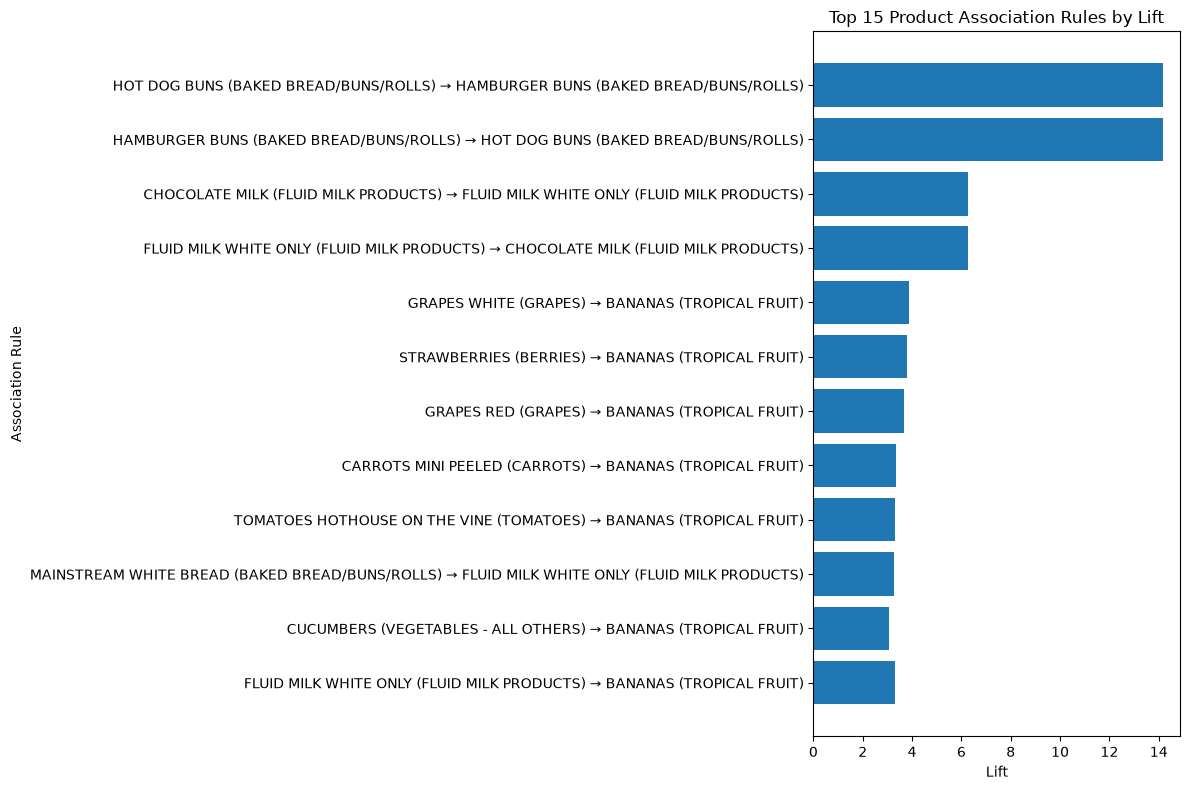

In [20]:
import matplotlib.pyplot as plt

top_rules = (
    interpretable_rules
    .sort_values("lift", ascending=False)
    .head(15)
    .copy()
)

top_rules["rule"] = top_rules.apply(
    lambda row: f"{', '.join(row['antecedents'])} → {', '.join(row['consequents'])}",
    axis=1
)

top_rules = top_rules.sort_values("lift", ascending=True)

plt.figure(figsize=(12, 8))
plt.barh(top_rules["rule"], top_rules["lift"])

plt.xlabel("Lift")
plt.ylabel("Association Rule")
plt.title("Top 15 Product Association Rules by Lift")
plt.tight_layout()
plt.show()

#### Cell 21 – Visualise Support, Confidence and Lift

This plot compares all Apriori association rules using support and confidence, with colour representing lift. It helps identify rules that combine strong association with reasonable frequency and confidence.

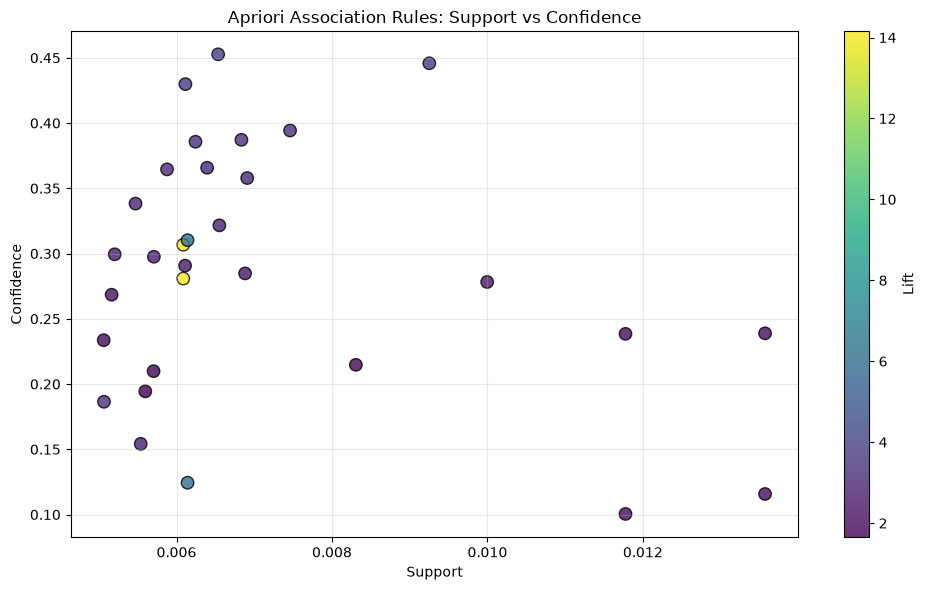

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rules_apriori["support"],
    rules_apriori["confidence"],
    c=rules_apriori["lift"],
    cmap="viridis",
    s=80,
    alpha=0.8,
    edgecolors="black"
)

plt.colorbar(scatter, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Apriori Association Rules: Support vs Confidence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Cell 22 – Identify High-Confidence Association Rules

This step identifies rules with confidence of at least 30% and displays them in descending order of lift. This is an exploratory filter to help interpret the stronger rules, not a replacement for the original mining thresholds.

In [22]:
high_confidence_rules = rules_apriori[
    rules_apriori["confidence"] >= 0.30
].copy()

high_confidence_rules = high_confidence_rules.sort_values(
    by="lift",
    ascending=False
)

print("Rules with confidence >= 30%:", len(high_confidence_rules))

display(
    high_confidence_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].reset_index(drop=True)
)

Rules with confidence >= 30%: 13


,antecedents,consequents,support,confidence,lift
0,(1098066),(826249),0.006087,0.306746,14.152721
1,(908531),(995242),0.006142,0.310263,6.283200
2,(866211),(1082185),0.006536,0.452686,3.861179
3,(1127831),(1082185),0.009252,0.445836,3.802749
4,(878996),(1082185),0.006114,0.429837,3.666286
5,(961554),(1082185),0.007461,0.394299,3.363166
6,(1126899),(1082185),0.006835,0.387154,3.302227
7,(854852),(1082185),0.006244,0.385700,3.289826
8,(1070820),(1082185),0.006394,0.365766,3.119794
9,(1058997),(1082185),0.005878,0.364502,3.109014


#### Cell 23 – Interpret High-Confidence Rules Using Product Categories

This step maps the product IDs in the selected rules to their available commodity and sub-commodity descriptions. It makes the strongest rules easier to interpret without changing the original product-level mining results.

In [23]:
product_description_lookup = (
    rule_product_details
    .assign(PRODUCT_ID=lambda x: x["PRODUCT_ID"].astype(str))
    .set_index("PRODUCT_ID")
    .apply(
        lambda row: f'{row["SUB_COMMODITY_DESC"]} ({row["COMMODITY_DESC"]})',
        axis=1
    )
    .to_dict()
)

def describe_product_set(product_set):
    return ", ".join(
        product_description_lookup.get(str(product_id), f"Unknown ({product_id})")
        for product_id in product_set
    )

high_confidence_interpretable = high_confidence_rules.copy()

high_confidence_interpretable["antecedent_description"] = (
    high_confidence_interpretable["antecedents"].apply(describe_product_set)
)

high_confidence_interpretable["consequent_description"] = (
    high_confidence_interpretable["consequents"].apply(describe_product_set)
)

display(
    high_confidence_interpretable[
        [
            "antecedent_description",
            "consequent_description",
            "support",
            "confidence",
            "lift"
        ]
    ].reset_index(drop=True)
)

,antecedent_description,consequent_description,support,confidence,lift
0,HOT DOG BUNS (BAKED BREAD/BUNS/ROLLS),HAMBURGER BUNS (BAKED BREAD/BUNS/ROLLS),0.006087,0.306746,14.152721
1,CHOCOLATE MILK (FLUID MILK PRODUCTS),FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS),0.006142,0.310263,6.283200
2,GRAPES WHITE (GRAPES),BANANAS (TROPICAL FRUIT),0.006536,0.452686,3.861179
3,STRAWBERRIES (BERRIES),BANANAS (TROPICAL FRUIT),0.009252,0.445836,3.802749
4,GRAPES RED (GRAPES),BANANAS (TROPICAL FRUIT),0.006114,0.429837,3.666286
5,CARROTS MINI PEELED (CARROTS),BANANAS (TROPICAL FRUIT),0.007461,0.394299,3.363166
6,FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS),BANANAS (TROPICAL FRUIT),0.006835,0.387154,3.302227
7,TOMATOES HOTHOUSE ON THE VINE (TOMATOES),BANANAS (TROPICAL FRUIT),0.006244,0.385700,3.289826
8,FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS),BANANAS (TROPICAL FRUIT),0.006394,0.365766,3.119794
9,FLUID MILK WHITE ONLY (FLUID MILK PRODUCTS),BANANAS (TROPICAL FRUIT),0.005878,0.364502,3.109014


#### Cell 24 – Save Association Rule Mining Results

This step saves the frequent itemsets, association rules, interpreted rules and algorithm comparison results in the planned output directory. The original transaction dataset remains unchanged.

In [24]:
from pathlib import Path

output_dir = Path("../data/processed/association_rule_mining")
output_dir.mkdir(parents=True, exist_ok=True)

# Save frequent itemsets
frequent_itemsets_apriori.to_csv(
    output_dir / "frequent_itemsets_apriori.csv",
    index=False
)

frequent_itemsets_fpgrowth.to_csv(
    output_dir / "frequent_itemsets_fpgrowth.csv",
    index=False
)

# Save association rules
rules_apriori.to_csv(
    output_dir / "association_rules_apriori.csv",
    index=False
)

rules_fpgrowth.to_csv(
    output_dir / "association_rules_fpgrowth.csv",
    index=False
)

# Save interpreted and selected rules
high_confidence_interpretable.to_csv(
    output_dir / "high_confidence_interpretable_rules.csv",
    index=False
)

# Save algorithm comparisons
itemset_comparison.to_csv(
    output_dir / "itemset_comparison.csv",
    index=False
)

rule_comparison.to_csv(
    output_dir / "rule_comparison.csv",
    index=False
)

print("Results saved successfully.")
print("Output directory:", output_dir.resolve())
print("\nSaved files:")

for file_path in sorted(output_dir.iterdir()):
    if file_path.is_file():
        print(file_path.name)

Results saved successfully.
Output directory: /home/rohan/GitHub/effect-of-discount-on-customer-purchase/data/processed/association_rule_mining

Saved files:
association_rules_apriori.csv
association_rules_fpgrowth.csv
frequent_itemsets_apriori.csv
frequent_itemsets_fpgrowth.csv
high_confidence_interpretable_rules.csv
itemset_comparison.csv
rule_comparison.csv


#### Cell 25 – Save the Association Rules Visualisation

This step recreates the support-confidence scatter plot, with lift represented by colour, and saves it as a PNG file in the association rule mining output directory for future reference.

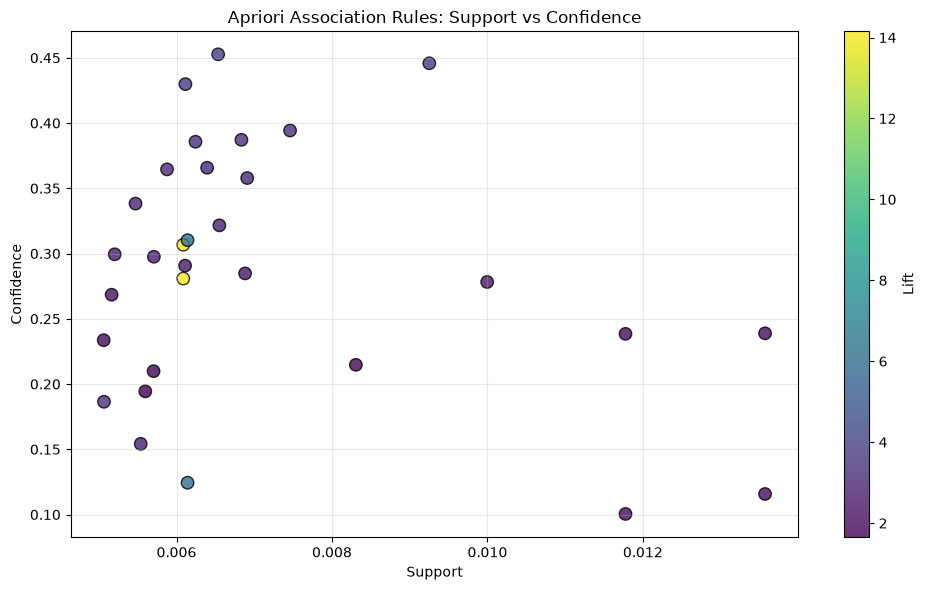

Visualisation saved to: /home/rohan/GitHub/effect-of-discount-on-customer-purchase/data/processed/association_rule_mining/support_confidence_lift_scatter.png


In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rules_apriori["support"],
    rules_apriori["confidence"],
    c=rules_apriori["lift"],
    cmap="viridis",
    s=80,
    alpha=0.8,
    edgecolors="black"
)

plt.colorbar(scatter, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Apriori Association Rules: Support vs Confidence")
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = output_dir / "support_confidence_lift_scatter.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Visualisation saved to:", plot_path.resolve())

#### Cell 26 – Verify Saved Association Rule Mining Outputs

This step checks whether all expected CSV files and the visualisation exist in the output directory. It also reads each CSV file to verify that the saved results are accessible and records their dimensions.

In [26]:
expected_files = [
    "frequent_itemsets_apriori.csv",
    "frequent_itemsets_fpgrowth.csv",
    "association_rules_apriori.csv",
    "association_rules_fpgrowth.csv",
    "high_confidence_interpretable_rules.csv",
    "itemset_comparison.csv",
    "rule_comparison.csv",
    "support_confidence_lift_scatter.png"
]

print("OUTPUT FILE VERIFICATION")
print("-" * 60)

verification_results = []

for filename in expected_files:
    file_path = output_dir / filename
    exists = file_path.exists()

    if exists:
        size_kb = file_path.stat().st_size / 1024

        if file_path.suffix == ".csv":
            saved_df = pd.read_csv(file_path)
            details = f"{saved_df.shape[0]} rows, {saved_df.shape[1]} columns"
        else:
            details = f"{size_kb:.2f} KB"

    else:
        size_kb = None
        details = "File missing"

    verification_results.append({
        "file": filename,
        "exists": exists,
        "size_kb": round(size_kb, 2) if size_kb is not None else None,
        "details": details
    })

verification_df = pd.DataFrame(verification_results)
display(verification_df)

print("\nAll expected files verified:",
      verification_df["exists"].all())

OUTPUT FILE VERIFICATION
------------------------------------------------------------


,file,exists,size_kb,details
0,frequent_itemsets_apriori.csv,True,7.29,"164 rows, 2 columns"
1,frequent_itemsets_fpgrowth.csv,True,7.29,"164 rows, 2 columns"
2,association_rules_apriori.csv,True,8.22,"31 rows, 14 columns"
3,association_rules_fpgrowth.csv,True,8.22,"31 rows, 14 columns"
4,high_confidence_interpretable_rules.csv,True,4.38,"13 rows, 16 columns"
5,itemset_comparison.csv,True,11.46,"164 rows, 4 columns"
6,rule_comparison.csv,True,15.40,"31 rows, 27 columns"
7,support_confidence_lift_scatter.png,True,165.97,165.97 KB



All expected files verified: True


#### Cell 27 – Document Key Findings

This step records the main findings from association rule mining, including the frequent itemsets, strongest associations and comparison of Apriori and FP-Growth. These findings will serve as the basis for the notebook's final interpretation and conclusion.

In [27]:
findings = {
    "Total cleaned baskets": 253991,
    "Candidate products": 137,
    "Minimum support": min_support,
    "Apriori frequent itemsets": len(frequent_itemsets_apriori),
    "FP-Growth frequent itemsets": len(frequent_itemsets_fpgrowth),
    "Apriori association rules": len(rules_apriori),
    "FP-Growth association rules": len(rules_fpgrowth),
    "Rules with confidence >= 30%": len(high_confidence_rules),
    "Highest lift": round(rules_apriori["lift"].max(), 6),
    "Mean confidence": round(rules_apriori["confidence"].mean(), 6),
    "Mean lift": round(rules_apriori["lift"].mean(), 6),
    "Common frequent itemsets": len(common_itemsets),
    "Common association rules": len(common_rules),
    "Maximum itemset support difference": 0.0,
    "Maximum rule metric difference": 0.0
}

findings_df = pd.DataFrame(
    list(findings.items()),
    columns=["Metric", "Value"]
)

display(findings_df)

findings_path = output_dir / "key_findings.csv"
findings_df.to_csv(findings_path, index=False)

print("Key findings saved to:", findings_path.resolve())

,Metric,Value
0,Total cleaned baskets,253991.000000
1,Candidate products,137.000000
2,Minimum support,0.005000
3,Apriori frequent itemsets,164.000000
4,FP-Growth frequent itemsets,164.000000
5,Apriori association rules,31.000000
6,FP-Growth association rules,31.000000
7,Rules with confidence >= 30%,13.000000
8,Highest lift,14.152721
9,Mean confidence,0.286185


Key findings saved to: /home/rohan/GitHub/effect-of-discount-on-customer-purchase/data/processed/association_rule_mining/key_findings.csv


#### Cell 28 – Document Limitations of the Analysis

This step records the limitations of the association rule mining analysis, including product selection, support thresholds and interpretation constraints. These limitations are considered when drawing conclusions from the discovered associations.

In [28]:
limitations = [
    {
        "Limitation": "Candidate product selection",
        "Explanation": "Only 137 products meeting the 0.5% basket-frequency threshold were selected, so less frequent products were not included in mining."
    },
    {
        "Limitation": "Minimum support threshold",
        "Explanation": "The 0.5% minimum support threshold excludes combinations occurring in fewer than 0.5% of all cleaned baskets."
    },
    {
        "Limitation": "Maximum itemset size",
        "Explanation": "Mining was initially restricted to itemsets containing at most three products. No three-product frequent itemsets were found."
    },
    {
        "Limitation": "Category exclusion",
        "Explanation": "Records belonging to COUPON/MISC ITEMS were excluded to avoid including gasoline-related shopping-trip combinations."
    },
    {
        "Limitation": "Product descriptions",
        "Explanation": "Different product IDs can share the same sub-commodity description, so category-level interpretations may appear repetitive."
    },
    {
        "Limitation": "Association is not causation",
        "Explanation": "Association rules identify purchasing patterns but cannot establish that buying one product causes the purchase of another."
    },
    {
        "Limitation": "Basket-level analysis",
        "Explanation": "The analysis identifies product combinations within baskets and does not directly establish household-level purchasing preferences."
    }
]

limitations_df = pd.DataFrame(limitations)

display(limitations_df)

limitations_path = output_dir / "analysis_limitations.csv"
limitations_df.to_csv(limitations_path, index=False)

print("Analysis limitations saved to:", limitations_path.resolve())

,Limitation,Explanation
0,Candidate product selection,Only 137 products meeting the 0.5% basket-freq...
1,Minimum support threshold,The 0.5% minimum support threshold excludes co...
2,Maximum itemset size,Mining was initially restricted to itemsets co...
3,Category exclusion,Records belonging to COUPON/MISC ITEMS were ex...
4,Product descriptions,Different product IDs can share the same sub-c...
5,Association is not causation,Association rules identify purchasing patterns...
6,Basket-level analysis,The analysis identifies product combinations w...


Analysis limitations saved to: /home/rohan/GitHub/effect-of-discount-on-customer-purchase/data/processed/association_rule_mining/analysis_limitations.csv


#### Conclusion

Association rule mining was performed on 253,991 cleaned retail baskets using 137 candidate products and a minimum support threshold of 0.5%.

Apriori and FP-Growth identified 164 frequent itemsets each and generated 31 association rules each. Both algorithms produced identical itemsets and rule metrics under the same parameters.

The strongest association was between hot dog buns and hamburger buns, with a lift of 14.15. Chocolate milk and white milk also showed a strong association, with a lift of 6.28. Several fruit and vegetable products were associated with bananas.

A total of 13 rules had confidence of at least 30%. These findings highlight combinations of products that frequently occur together within retail baskets.

The analysis demonstrates the importance of evaluating support, confidence and lift together. However, association rules describe purchasing patterns and do not establish causal relationships or household-level preferences.

Overall, association rule mining provided useful insights into basket-level product relationships, while Apriori and FP-Growth produced consistent results under the selected parameters.